# Agrupamiento de incumplimientos: dónde se usa mal la prueba binomial y la reproducción del documento de trabajo 14 de BCBS

**Pregunta:** ¿Cuánto infla una correlación de activos pequeña la tasa de falsas alarmas de las pruebas que suponen incumplimientos independientes, y reproduce el motor lo que imprimió el documento de trabajo 14 de BCBS?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 a 03 de este tema (la tasa, el tamaño de cada prueba, las probabilidades de rechazo exactas)
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- calcular la correlación de incumplimiento que implica una correlación de activos y el factor con que infla la varianza de un conteo de incumplimientos;
- leer el tamaño exacto de las pruebas binomial, de Jeffreys y binomial corregida por Vasicek bajo agrupamiento, y decir cuál se rompe primero;
- medir por simulación el tamaño de las pruebas sin forma cerrada a medida que crece la correlación de activos;
- recalcular con el motor la confianza verdadera de una prueba binomial de 99,9 % y compararla con la aproximación del documento de trabajo 14 de BCBS;
- repetir un escenario del documento con una semilla nueva y juzgar, celda por celda, si el motor reproduce lo que el documento imprimió.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son la familia `clustering` del caso C22, validar al validador. En cada conjunto las PD que reciben las pruebas son exactamente las correctas, y los incumplimientos comparten un factor sistemático con una correlación de activos $\rho$ en una escalera de 0 a 20 %. Un rechazo es por tanto siempre una falsa alarma, y su tasa es el tamaño verdadero de la prueba bajo agrupamiento. La familia guarda además, en `golden`, las tasas publicadas del documento de trabajo 14 de BCBS, tablas 7 y 8 (144 celdas), citadas del documento. Los conjuntos vienen de generadores de verdad conocida de `riskvalidation.generators` (licencia MIT, clase `generated`).

- **Archivo que se lee:** `data/derived/C22/clustering.json`, claves `outputs` (simulaciones, generadores, escalera, la curva exacta y las celdas publicadas) y `provenance`.
- **Qué se toma de él:** la configuración y la semilla de cada peldaño, la malla de PD de la figura del documento y sus tasas publicadas.

La celda siguiente carga el archivo e imprime la escalera con las versiones del motor.

In [2]:
# Cargar la familia de agrupamiento e indexar sus simulaciones por clave
LANG = "es"
ROOT = Path("../../..").resolve()
clustering = json.loads((ROOT / "data" / "derived" / "C22" / "clustering.json").read_text(encoding="utf-8"))
out = clustering["outputs"]
rows = {row["key"]: row for row in out["simulations"]}
ladder = out["ladder"]["values"]
golden = out["golden"][0]
print("correlaciones de activos de la escalera:", ladder)
print("calculado con riskvalidation", clustering["provenance"]["riskvalidation_version"])
print("instalado", rv.__version__)

correlaciones de activos de la escalera: [0.0, 0.02, 0.05, 0.1, 0.15, 0.2]
calculado con riskvalidation 1.0.1
instalado 1.0.1


## Método

**Un factor sistemático.** En el modelo de un factor del documento de trabajo, y de Vasicek, el deudor $i$ incumple cuando su valor de activos cae bajo un umbral, y los valores de activos comparten un factor $x \sim N(0,1)$ con correlación $\rho$. Dado $x$ los incumplimientos son independientes con la PD condicional

$$p(x) = \Phi\!\left(\frac{\Phi^{-1}(\pi) - \sqrt{\rho}\,x}{\sqrt{1-\rho}}\right),$$

y el conteo de incumplimientos de $n$ deudores tiene varianza $n\pi(1-\pi)\,[1 + (n-1)\rho_D]$, donde $\rho_D$ es la correlación de incumplimiento. Una prueba que fija su valor crítico como si $\rho_D$ fuera cero rechaza demasiado, porque la dispersión real del conteo es la mayor. Los pasos miden cuánto, de forma exacta para las pruebas de conteo y por simulación para las demás, y luego contrastan el motor con el documento.

### Paso 1: una correlación de incumplimiento pequeña, una varianza grande

El `default_correlation` del motor evalúa $\rho_D$ para una PD y una correlación de activos. La celda siguiente la imprime para cada peldaño con una PD de 1 %, junto al factor de varianza $1 + (n-1)\rho_D$ para 1.000 deudores, y dibuja el factor sobre una malla fina de correlaciones de activos.

correlación de activos 0.00 | correlación de incumplimiento 0.000%
   factor de varianza 1.00
correlación de activos 0.02 | correlación de incumplimiento 0.151%
   factor de varianza 2.51
correlación de activos 0.05 | correlación de incumplimiento 0.410%
   factor de varianza 5.10
correlación de activos 0.10 | correlación de incumplimiento 0.936%
   factor de varianza 10.35
correlación de activos 0.15 | correlación de incumplimiento 1.597%
   factor de varianza 16.95
correlación de activos 0.20 | correlación de incumplimiento 2.413%
   factor de varianza 25.11


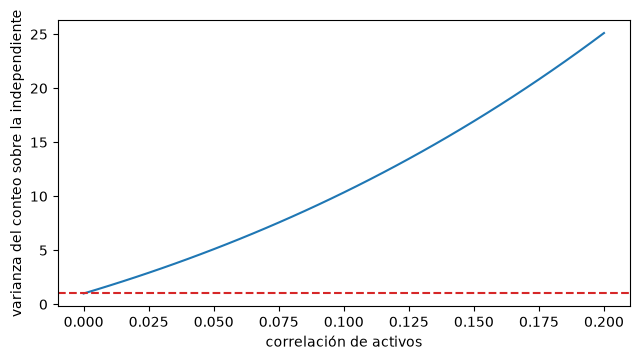

In [3]:
# Correlación de incumplimiento implícita en cada correlación de activos e inflación de la varianza del conteo
from riskvalidation.generators.counts import default_correlation

grid = np.linspace(0.0, 0.2, 41)
inflation = [1 + 999 * (default_correlation(0.01, r) if r > 0 else 0.0) for r in grid]
for rho in ladder:
    rho_d = default_correlation(0.01, rho) if rho > 0 else 0.0
    print(f"correlación de activos {rho:.2f} | correlación de incumplimiento {100 * rho_d:.3f}%")
    print(f"   factor de varianza {1 + 999 * rho_d:.2f}")
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(grid, inflation)
ax.axhline(1.0, color="tab:red", linestyle="--")
ax.set_xlabel("correlación de activos")
ax.set_ylabel("varianza del conteo sobre la independiente")
fig.tight_layout()
plt.show()

Una correlación de activos de 5 % es una correlación de incumplimiento de solo 0,410 %, y aun así multiplica por 5,10 la varianza del conteo de incumplimientos de una cartera de 1.000 deudores. Con 10 % el factor es 10,35 y con 20 % llega a 25,11. La curva es casi una recta en $\rho$ porque $\rho_D$ crece más o menos en proporción, y el factor crece también con el número de deudores. Una prueba que supone para el conteo la varianza independiente mira una dispersión de cinco a veinticinco veces demasiado pequeña.

### Paso 2: el tamaño exacto de las pruebas de conteo bajo agrupamiento

La celda siguiente pide a `rejection_probability` el tamaño exacto al 5 % de las pruebas binomial, de Jeffreys y binomial corregida por Vasicek para 1.000 deudores con una PD de 1 % exactamente correcta, a medida que la correlación de activos verdadera sube de 0 a 20 %. La prueba corregida supone una correlación de 12 %. La celda imprime los tamaños con cuatro correlaciones y dibuja las tres sobre una malla de 21 valores.

pd.binomial          [0.0479, 0.1775, 0.1969, 0.1911]
pd.jeffreys          [0.0479, 0.1775, 0.1969, 0.1911]
pd.binomial_vasicek  [0.0, 0.0146, 0.0414, 0.0711]
correlación de activos de esos tamaños: [0.0, 0.05, 0.1, 0.2]


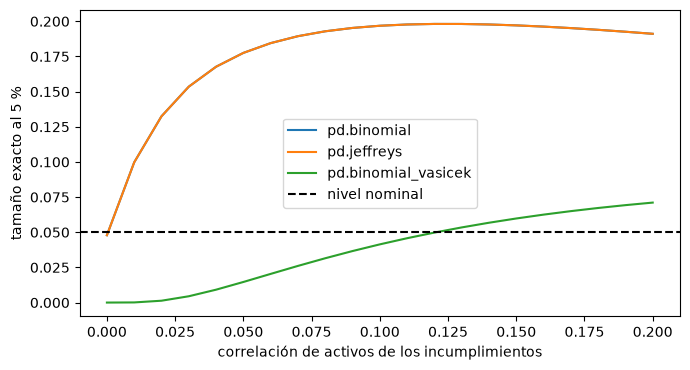

In [4]:
# Tamaño exacto al 5 % de las tres pruebas de conteo a lo largo de la escalera de correlación de activos
from riskvalidation.harness.exact import rejection_probability

count_tests = {"pd.binomial": {}, "pd.jeffreys": {}, "pd.binomial_vasicek": {"rho": 0.12}}
fine = np.linspace(0.0, 0.2, 21)
sizes = {}
for test, kw in count_tests.items():
    exact = [rejection_probability(test, 1000, 0.01, 0.05, pd_true=0.01, rho_true=r, **kw) for r in fine]
    sizes[test] = [item["probability"] for item in exact]
    print(f"{test:20s}", [round(sizes[test][i], 4) for i in (0, 5, 10, 20)])
print("correlación de activos de esos tamaños:", [round(float(fine[i]), 2) for i in (0, 5, 10, 20)])
fig, ax = plt.subplots(figsize=(7, 3.8))
for test in count_tests:
    ax.plot(fine, sizes[test], label=test)
ax.axhline(0.05, color="black", linestyle="--", label="nivel nominal")
ax.set_xlabel("correlación de activos de los incumplimientos")
ax.set_ylabel("tamaño exacto al 5 %")
ax.legend()
fig.tight_layout()
plt.show()

Las pruebas binomial y de Jeffreys comparten una sola curva al 5 %, pues ambas rechazan desde el mismo conteo. Su tamaño exacto sube de 0,0479 con incumplimientos independientes a 0,1775 con una correlación de activos de 5 %, 0,1969 con 10 % y 0,1911 con 20 %: una prueba vendida como de 5 % rechaza un modelo correcto una vez de cada cinco. La prueba corregida queda bajo su nivel cuando la correlación verdadera es menor que la supuesta, con 0,0146 con 5 %, y solo lo pasa más allá de 12 %, con 0,0711 con 20 %. La corrección no remedia una correlación equivocada, solo la correcta.

### Paso 3: las pruebas sin forma cerrada

La prueba chi-cuadrado sobre siete grados, Hosmer-Lemeshow (1980) y Spiegelhalter (1986) suponen todas incumplimientos independientes, y la prueba normal multianual y los semáforos son las pruebas del documento de trabajo para series de tiempo. Para ellas la única medición es una tasa simulada. La celda siguiente reconstruye el generador de cada peldaño desde el archivo, simula cada prueba con 1.000 repeticiones, imprime los tamaños a lo largo de la escalera y los dibuja contra el 5 % nominal.

pd.chi2_grades           [0.039, 0.476, 0.665, 0.745, 0.833, 0.871]
pd.hosmer_lemeshow       [0.051, 0.514, 0.633, 0.764, 0.829, 0.868]
pd.spiegelhalter         [0.038, 0.308, 0.354, 0.311, 0.353, 0.344]
pd.normal_multiperiod    [0.083, 0.091, 0.077, 0.056, 0.034, 0.039]
pd.traffic_lights        [0.037, 0.108, 0.109, 0.107, 0.074, 0.06]


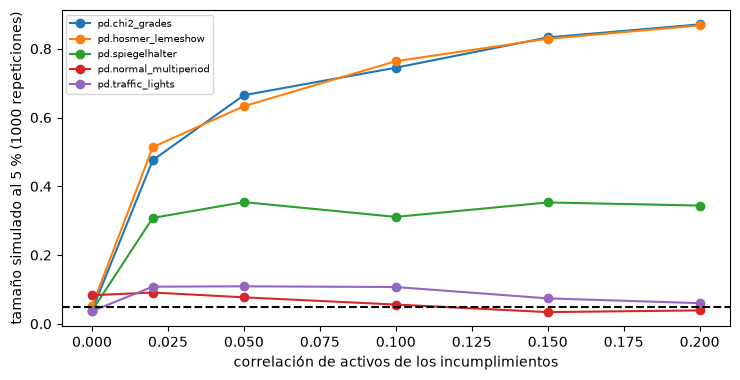

In [5]:
# Simular las cinco pruebas sin forma cerrada a lo largo de la escalera y dibujar su tamaño
from riskvalidation.generators.counts import DefaultCounts, feed_grades, feed_series
from riskvalidation.generators.scores import LogisticPortfolio
from riskvalidation.harness.run import simulate

CLASSES = {cls.name: cls for cls in (DefaultCounts, LogisticPortfolio)}
open_tests = ("pd.chi2_grades", "pd.hosmer_lemeshow", "pd.spiegelhalter", "pd.normal_multiperiod", "pd.traffic_lights")
fig, ax = plt.subplots(figsize=(7.5, 3.9))
for test in open_tests:
    rates = []
    for rho in ladder:
        row = rows[f"{test}@rho{rho:g}"]
        cfg = out["generators"][row["generator"]]
        shape = cfg["config"].get("obligors", [[0]])
        feed = feed_series() if len(shape) > 1 else feed_grades()
        generator = CLASSES[cfg["name"]](**cfg["config"])
        feed = None if cfg["name"] == "logistic_portfolio" else feed
        run = simulate(test, generator, n_rep=1000, seed=row["seed"], feed=feed)
        rates.append(run.rates["p<0.05"].rate)
    ax.plot(ladder, rates, "o-", label=test)
    print(f"{test:24s}", [round(r, 3) for r in rates])
ax.axhline(0.05, color="black", linestyle="--")
ax.set_xlabel("correlación de activos de los incumplimientos")
ax.set_ylabel("tamaño simulado al 5 % (1000 repeticiones)")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

Hosmer-Lemeshow y la prueba chi-cuadrado sobre grados se siguen de cerca: 0,514 y 0,476 con una correlación de activos de 2 %, y 0,868 y 0,871 con 20 %. Comparan la brecha de cada grupo con una varianza independiente, y las brechas agrupadas son grandes. Spiegelhalter se ve menos afectada pero aun así rechaza cerca de un tercio de las veces, entre 0,308 y 0,354. Las dos pruebas de series de tiempo se comportan distinto: la prueba normal cae a 0,039 con 20 % y los semáforos a 0,060. En esta escalera los años comparten una correlación de factor de 0,2 siempre que la correlación de activos es positiva, así que sus errores anuales tampoco son independientes, y el tamaño se mueve con el escenario.

### Paso 4: la figura 9 del documento de trabajo, recalculada

El documento grafica la confianza verdadera de una prueba binomial con confianza nominal de 99,9 % cuando los incumplimientos siguen la correlación corporativa de Basilea, que baja de 24 % con una PD cercana a cero a 12 % con una PD alta. La confianza verdadera es la probabilidad de no rechazar. La celda siguiente la calcula de forma exacta con `rejection_probability`, y con la aproximación del documento con `wp14_true_confidence`, para cuatro tamaños de cartera sobre la malla de PD del documento, y dibuja ambas.

n =  100 | confianza verdadera, exacta: de 0.984 a 0.921
n =  400 | confianza verdadera, exacta: de 0.948 a 0.812
n = 1000 | confianza verdadera, exacta: de 0.904 a 0.748
n = 1900 | confianza verdadera, exacta: de 0.875 a 0.710


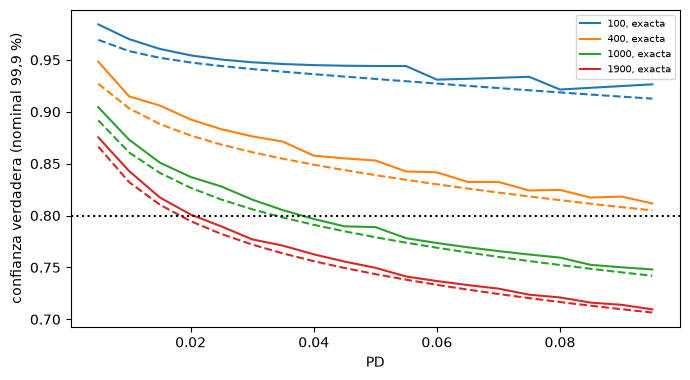

In [6]:
# Confianza verdadera de una prueba binomial de 99,9 % con correlación de Basilea, exacta y aproximada
from riskvalidation.harness.exact import wp14_true_confidence
from riskvalidation.regulatory.irb import correlation

pds = np.array(out["exact_curves"][0]["x"])
fig, ax = plt.subplots(figsize=(7, 3.9))
for index, n in enumerate((100, 400, 1000, 1900)):
    rhos = [correlation("corporate", p) for p in pds]
    tails = [rejection_probability("pd.binomial", n, p, 0.001, rho_true=r)["probability"] for p, r in zip(pds, rhos)]
    exact_y = [1 - t for t in tails]
    approx_y = [wp14_true_confidence(p, n, r, 0.999) for p, r in zip(pds, rhos)]
    ax.plot(pds, exact_y, color=f"C{index}", label=f"{n}, exacta")
    ax.plot(pds, approx_y, color=f"C{index}", linestyle="--")
    print(f"n = {n:4d} | confianza verdadera, exacta: de {max(exact_y):.3f} a {min(exact_y):.3f}")
ax.axhline(0.8, color="black", linestyle=":")
ax.set_xlabel("PD")
ax.set_ylabel("confianza verdadera (nominal 99,9 %)")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

La aproximación punteada sigue de cerca la curva exacta en las carteras grandes, y ambas bajan al crecer la cartera: con 100 deudores la confianza verdadera queda entre 0,984 y 0,921, con 400 entre 0,948 y 0,812, con 1.000 entre 0,904 y 0,748 y con 1.900 entre 0,875 y 0,710. La línea de puntos marca 80 %: con una cartera de 1.000 o más, una prueba vendida como de 99,9 % de confianza tiene una confianza verdadera que baja de 0,8 en parte del rango de PD, un tamaño verdadero sobre 20 %. Las carteras más grandes agravan el problema, no lo alivian.

### Paso 5: un escenario del documento, repetido con una semilla nueva

El documento corrió las pruebas normal y de semáforos sobre cinco años de 1.000 deudores con 25.000 corridas por escenario. El escenario DC_LC de su tabla 5 tiene una correlación de factor de 0,2 entre años, una correlación de activos de 5 % cada año y una PD de 3 %. La celda siguiente lo construye con `DefaultCounts.over_years`, corre ambas pruebas con 25.000 repeticiones y una semilla que el documento nunca vio, y pone cada error tipo I junto al publicado con `agrees_with_published`.

DC_LC, normal    0.05 | publicado 0.070 | corrida nueva 0.0704 | z +0.16 | True
DC_LC, normal    0.01 | publicado 0.026 | corrida nueva 0.0265 | z +0.36 | True
DC_LC, traffic   0.05 | publicado 0.113 | corrida nueva 0.1161 | z +1.08 | True
DC_LC, traffic   0.01 | publicado 0.024 | corrida nueva 0.0235 | z -0.35 | True


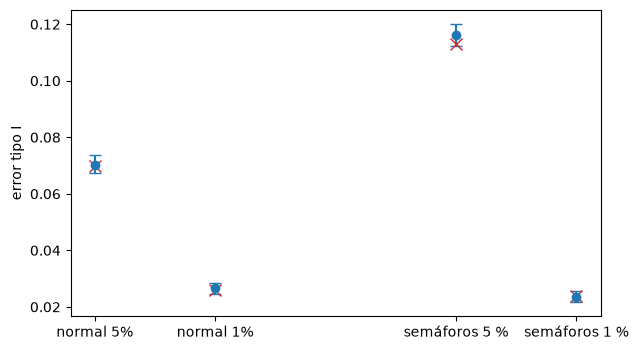

In [7]:
# Repetir el escenario DC_LC de la tabla 5 de WP14 con otra semilla frente a los errores publicados
from riskvalidation.harness.rates import agrees_with_published

scenario = DefaultCounts.over_years([1000] * 5, [0.03] * 5, rho=0.05, theta=0.2)
published = {(c["row"], c["column"]): c["published"] for c in golden["cells"] if c["table"] == "Table 7"}
fig, ax = plt.subplots(figsize=(6.5, 3.6))
cases = (("pd.normal_multiperiod", {}, "DC_LC, normal"), ("pd.traffic_lights", {"ties": "upper"}, "DC_LC, traffic"))
for position, (test, kw, name) in enumerate(cases):
    run = simulate(test, scenario, n_rep=25000, seed=2026, feed=feed_series(), test_kwargs=kw)
    for shift, (rule, level) in enumerate((("p<0.05", "0.05"), ("p<0.01", "0.01"))):
        measured, pub = run.rates[rule], published[(name, level)]
        ok, z = agrees_with_published(measured, pub, golden["runs_published"])
        low, high = measured.interval
        print(f"{name:16s} {level} | publicado {pub:.3f} | corrida nueva {measured.rate:.4f} | z {z:+.2f} | {ok}")
        x = position * 3 + shift
        errors = [[measured.rate - low], [high - measured.rate]]
        ax.errorbar(x, measured.rate, yerr=errors, fmt="o", capsize=4, color="tab:blue")
        ax.plot(x, pub, "x", color="tab:red", markersize=9)
ax.set_xticks([0, 1, 3, 4])
ax.set_xticklabels(["normal 5%", "normal 1%", "semáforos 5 %", "semáforos 1 %"])
ax.set_ylabel("error tipo I")
fig.tight_layout()
plt.show()

Los cuatro errores tipo I concuerdan con el documento: la prueba normal da 0,0704 al 5 % frente al 0,070 publicado y 0,0265 al 1 % frente a 0,026, y los semáforos dan 0,1161 frente a 0,113 y 0,0235 frente a 0,024, con diferencias estandarizadas entre -0,35 y 1,08. Es una repetición independiente, con el motor y una semilla nueva, y cae dentro del error de Monte Carlo de números impresos en 2005. El tamaño de 0,1161 de los semáforos es además la ilustración más clara de la tesis del documento: con años correlacionados, una prueba de 5 % rechaza un modelo correcto una vez de cada nueve.

### Paso 6: las tablas 7 y 8, celda por celda

El documento imprimió el error tipo I (tabla 7) y el error tipo II (tabla 8) de las dos pruebas de series de tiempo con seis niveles en muchos escenarios. El archivo guarda las 144 celdas publicadas con la tasa que midió el motor. La celda siguiente calcula la diferencia estandarizada de cada celda con `agrees_with_published` e imprime cuántas concuerdan, la diferencia media y la mayor, y la celda que no concuerde, y luego dibuja el histograma de las diferencias con el límite de 3,29.

celdas: 144 | z medio: -0.112
mayor z absoluto: 5.81
celdas que concuerdan: 143 | que no concuerdan: 1
('Table 8', 'DV_LV, traffic', '0.001', 0.955, 0.9436)


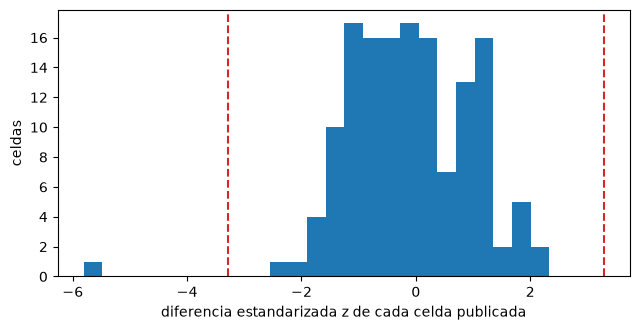

In [8]:
# Diferencia estandarizada de cada celda publicada de las tablas 7 y 8 de WP14
from riskvalidation.harness.rates import Rate

n_runs = golden["runs"]
zs, misses = [], []
for cell in golden["cells"]:
    measured = Rate(round(cell["measured"] * n_runs), n_runs)
    ok, z = agrees_with_published(measured, cell["published"], golden["runs_published"])
    zs.append(z)
    if not ok:
        misses.append((cell["table"], cell["row"], cell["column"], cell["published"], round(cell["measured"], 4)))
print("celdas:", len(zs), "| z medio:", round(float(np.mean(zs)), 3))
print("mayor z absoluto:", round(float(np.max(np.abs(zs))), 2))
print("celdas que concuerdan:", len(zs) - len(misses), "| que no concuerdan:", len(misses))
for miss in misses:
    print(miss)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(zs, bins=25, color="tab:blue")
ax.axvline(-3.29, color="tab:red", linestyle="--")
ax.axvline(3.29, color="tab:red", linestyle="--")
ax.set_xlabel("diferencia estandarizada z de cada celda publicada")
ax.set_ylabel("celdas")
fig.tight_layout()
plt.show()

Las diferencias se centran en cero, con una media de -0,112, así que el motor queda levemente bajo el documento en promedio, y 143 de las 144 celdas concuerdan. La excepción es la tabla 8, escenario DV_LV, semáforos, con nivel 0,001: el documento imprime 0,955 y el motor mide 0,9436, una diferencia estandarizada de 5,81 en valor absoluto. Es el único desacuerdo entre 144 celdas, así que los niveles vecinos de esa fila concuerdan, y la celda impresa parece un descuido del documento y no una falla del motor. Una reproducción debe declarar su excepción, no ocultarla.

## Resultados

**Respuesta:** Una correlación de activos de 5 %, una correlación de incumplimiento de apenas 0,410 %, multiplica por 5,10 la varianza del conteo de incumplimientos de 1.000 deudores y eleva el tamaño exacto de la prueba binomial al 5 % de 0,0479 a 0,1775; con 10 % el tamaño es 0,1969. Las pruebas sin forma cerrada también sufren: Hosmer-Lemeshow llega a 0,868 y la chi-cuadrado sobre grados a 0,871 con una correlación de activos de 20 %. El motor reproduce el documento de trabajo: la repetición del escenario DC_LC concuerda dentro del error de Monte Carlo (0,0704 frente a 0,070 para la prueba normal al 5 %), y 143 de las 144 celdas publicadas concuerdan.

- **El tamaño exacto zanja las pruebas de conteo.** La prueba corregida queda en 0,0146 con una correlación de activos de 5 %, bajo su nivel, y en 0,0711 con 20 %, sobre él, porque supone 12 %.
- **Las pruebas de series de tiempo yerran en ambos sentidos.** La prueba normal cae a 0,039 con 20 % mientras los semáforos llegan a 0,1161 en el escenario del documento.
- **Una cartera grande no ayuda.** Con 1.900 deudores la confianza verdadera de una prueba de 99,9 % baja hasta 0,710.
- **El único desacuerdo se explica.** La tabla 8, DV_LV, semáforos, nivel 0,001 muestra 5,81 unidades estandarizadas, y por ser la única de 144 apunta a la impresión.

La potencia bajo agrupamiento, donde el documento concluye que no existe una prueba realmente potente, se retoma en el notebook de estado del arte del tema.

## Resumen

- Una correlación de activos pequeña es una correlación de incumplimiento pequeña y una varianza grande del conteo: un factor de 5,10 con 5 % para 1.000 deudores.
- Las pruebas binomial y de Jeffreys, que suponen independencia, tienen un tamaño exacto de 0,1775 a 0,1969 con un 5 % nominal desde que la correlación de activos es 5 % o más.
- La corrección de Vasicek solo acierta cuando su correlación supuesta es la verdadera.
- Las pruebas de grados y de deudores rechazan de más bajo agrupamiento; las de series de tiempo pueden rechazar de menos o de más según el escenario.
- El motor repite el documento de trabajo: un escenario con semilla nueva concuerda, y 143 de 144 celdas publicadas concuerdan, con la excepción explicada.

**Qué probar después.** Repite el paso 5 con los escenarios de años independientes de la tabla 5 y compara los tamaños con los agrupados; luego lee el notebook 05.

## Referencias

- Morris, T. P., White, I. R. y Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): la prueba binomial y su tamaño verdadero bajo correlación (apéndice, Figura 9), el estudio de simulación de las pruebas normal y de semáforo (páginas 61 a 67, Tablas 5 a 8). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Spiegelhalter, D. J. (1986), Probabilistic prediction in patient management and clinical trials, Statistics in Medicine 5(5). https://doi.org/10.1002/sim.4780050506
- Este repositorio: `docs/design/features/c22-validator/requirements.md` y `data-pipeline/pipeline/cases/c22_validator.py`, que escribió el artefacto.